# 05. Финальное сравнение на test

**Единственное место, где используется test** (последняя неделя данных, дни 293.9–300.9).

**Протокол:**
- все модели обучены на train с ранней остановкой на val_a; признаки отобраны (E1) и h подобрано (E2) на val_a; выводы подтверждены на val_b;
- здесь **ничего не обучается и не подбирается**: загружаем сохранённые модели из `artifacts/E*/` и один раз считаем метрики на test;
- кандидаты, разбиение, параметры LightGBM и логрегрессии — одинаковые для всех экспериментов.

| эксперимент | признаки |
|---|---|
| **E0** | 36 ручных признаков (окна 7/30 дней и вся история) |
| **E1** | 10 признаков, автоматически отобранных из грамматики (~860) жадным отбором по GAUC |
| **E2** | 48 затухающих счётчиков, период полураспада h подобран на val_a |
| E0 + E1, E0 + E2 | ручные плюс автоматические |

In [1]:
import sys, time, resource, pickle
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def peak_ram_gb():
    """Пиковая память процесса (ядра ноутбука) с момента старта, ГБ."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

from src.candidates import load_candidates
from src.features import E0_FEATURES
from src.metrics import evaluate
from src.selection import catalog, load_matrix
from src.decay import load_decay

A = ROOT / "artifacts"
load = lambda p: pickle.load(open(A / p, "rb"))
R = {"E0": load("E0/results.pkl"), "E1": load("E1/results.pkl"), "E2": load("E2/results.pkl")}

cands = load_candidates()
te = cands.filter(pl.col("part") == "test")
tr_rate = cands.filter(pl.col("part") == "train")["label"].mean()
feats0 = pl.read_parquet(ROOT / "data" / "processed" / "features_E0.parquet")
X = (te.select("row_id")
     .join(feats0, on="row_id", how="left", maintain_order="left")
     .join(load_matrix(te, R["E1"]["features"], catalog()), on="row_id", how="left", maintain_order="left")
     .join(load_decay(te, R["E2"]["config"]), on="row_id", how="left", maintain_order="left"))
assert X["row_id"].equals(te["row_id"])
print(f"test: {te.height:,} строк, {te['uid'].n_unique():,} пользователей, доля label = {te['label'].mean():.3f} "
      f"(train {tr_rate:.3f})".replace(",", " "))

test: 728 949 строк  6 167 пользователей  доля label = 0.714 (train 0.682)


## 1. Метрики на test

In [2]:
F1, F2 = R["E1"]["features"], R["E2"]["features"]
MODELS = [  # (имя, файл модели, признаки, тип)
    ("E0 LightGBM", "E0/lgb.pkl", E0_FEATURES, "lgb"),
    ("E1 LightGBM", "E1/lgb.pkl", F1, "lgb"),
    ("E2 LightGBM", "E2/lgb.pkl", F2, "lgb"),
    ("E0 + E1 LightGBM", "E1/lgb_union.pkl", R["E1"]["union_features"], "lgb"),
    ("E0 + E2 LightGBM", "E2/lgb_union.pkl", [*E0_FEATURES, *F2], "lgb"),
    ("E0 логрегрессия", "E0/lr.pkl", E0_FEATURES, "lr"),
    ("E1 логрегрессия", "E1/lr.pkl", F1, "lr"),
    ("E2 логрегрессия", "E2/lr.pkl", F2, "lr"),
]
pred = te.select("row_id", "uid", "day", "label").with_columns(
    const=pl.lit(tr_rate), random=pl.Series(np.random.default_rng(0).uniform(0.01, 0.99, te.height)))
for name, path, cols, kind in MODELS:
    m = load(path)
    Xm = X.select(cols).to_numpy()
    p = m.predict(Xm, num_iteration=m.best_iteration) if kind == "lgb" else m.predict_proba(Xm)[:, 1]
    pred = pred.with_columns(pl.Series(name, p))
    del m, Xm

rows = [{"модель": n, **evaluate(pred, c)} for n, c in [("константа", "const"), ("случайный", "random")]]
rows += [{"модель": n, **evaluate(pred, n)} for n, *_ in MODELS]
test_m = pl.DataFrame(rows).drop("groups")
display(test_m.with_columns(pl.col(pl.Float64).round(4)))

модель,logloss,roc_auc,ndcg@10,recall@10,gauc
str,f64,f64,f64,f64,f64
"""константа""",0.6012,0.5,0.7187,0.4835,0.5
"""случайный""",0.9631,0.4997,0.7222,0.4833,0.5029
"""E0 LightGBM""",0.4553,0.8228,0.7708,0.5074,0.573
"""E1 LightGBM""",0.4563,0.8188,0.768,0.5066,0.5684
"""E2 LightGBM""",0.4522,0.822,0.7705,0.5078,0.5722
"""E0 + E1 LightGBM""",0.4504,0.8259,0.772,0.5087,0.5754
"""E0 + E2 LightGBM""",0.4465,0.8275,0.7721,0.5083,0.5757
"""E0 логрегрессия""",0.4633,0.8169,0.7613,0.5021,0.5653
"""E1 логрегрессия""",0.4632,0.8143,0.7607,0.5023,0.5626


## 2. Значимость разницы с E0 на test

Парный бутстреп по группам «пользователь × день» (1000 повторов): средняя разница GAUC и NDCG@10 на одних и тех же группах.

In [ ]:
def per_group(d, col, k=10):
    disc = 1.0 / np.log2(np.arange(2, k + 2))
    ideal = np.concatenate([[0.0], np.cumsum(disc)])
    tb = np.random.default_rng(0).random(d.height)

    g = (d.select("uid", "day", "label", col).with_columns(_tb=pl.Series(tb))
         .with_columns(rank=(pl.col(col).rank("dense", descending=True) + pl.col("_tb")).rank("ordinal").over("uid", "day"),
                       ar=pl.col(col).rank("average").over("uid", "day"),
                       npos=pl.col("label").sum().over("uid", "day"), n=pl.len().over("uid", "day"))
         #хотя один 0, хотя бы одна единица
         .filter((pl.col("npos") > 0) & (pl.col("npos") < pl.col("n")))
         #топ k
         .with_columns(gain=pl.when(pl.col("rank") <= k).then(pl.col("label") / (pl.col("rank") + 1).log(2)).otherwise(0.0))
         #наша группировка
         .group_by("uid", "day")
        #все необходимое
         .agg(dcg=pl.col("gain").sum(), npos=pl.col("npos").first(), n=pl.col("n").first(),
              prs=(pl.col("ar") * pl.col("label")).sum())
         .sort("uid", "day"))
    
    gauc = (g["prs"] - g["npos"] * (g["npos"] + 1) / 2) / (g["npos"] * (g["n"] - g["npos"]))
    ndcg = g["dcg"].to_numpy() / ideal[np.minimum(g["npos"].to_numpy(), k)]
    return gauc.to_numpy(), ndcg

PG = {n: per_group(pred, n) for n, *_ in MODELS if "LightGBM" in n}
idx = np.random.default_rng(1).integers(0, len(PG["E0 LightGBM"][0]), (1000, len(PG["E0 LightGBM"][0])))
boot = []


for n in ["E1 LightGBM", "E2 LightGBM", "E0 + E1 LightGBM", "E0 + E2 LightGBM"]:
    row = {"сравнение с E0": n}
    
    for j, met in enumerate(["GAUC", "NDCG@10"]):

        diff = PG[n][j] - PG["E0 LightGBM"][j]
        bs = diff[idx].mean(1)
        lo, hi = np.quantile(bs, [0.025, 0.975])

        row[f"Δ {met}"] = round(float(diff.mean()), 4)
        row[f"95% ДИ {met}"] = f"[{lo:+.4f}; {hi:+.4f}]"
        row[f"значимо ({met})"] = "да" if lo > 0 or hi < 0 else "нет"

    boot.append(row)


# E2 против E1 — отдельно
diff = PG["E2 LightGBM"][0] - PG["E1 LightGBM"][0]
bs = diff[idx].mean(1)
print(f"E2 − E1 по GAUC: {diff.mean():+.4f}, 95% ДИ [{np.quantile(bs, 0.025):+.4f}; {np.quantile(bs, 0.975):+.4f}]")
boot = pl.DataFrame(boot)
boot

E2 − E1 по GAUC: +0.0038, 95% ДИ [+0.0016; +0.0059]


сравнение с E0,Δ GAUC,95% ДИ GAUC,значимо (GAUC),Δ NDCG@10,95% ДИ NDCG@10,значимо (NDCG@10)
str,f64,str,str,f64,str,str
"""E1 LightGBM""",-0.0046,"""[-0.0071; -0.0022]""","""да""",-0.0027,"""[-0.0044; -0.0011]""","""да"""
"""E2 LightGBM""",-0.0008,"""[-0.0031; +0.0019]""","""нет""",-0.0003,"""[-0.0018; +0.0015]""","""нет"""
"""E0 + E1 LightGBM""",0.0024,"""[+0.0005; +0.0045]""","""да""",0.0012,"""[-0.0002; +0.0026]""","""нет"""
"""E0 + E2 LightGBM""",0.0027,"""[+0.0005; +0.0048]""","""да""",0.0014,"""[-0.0001; +0.0028]""","""нет"""


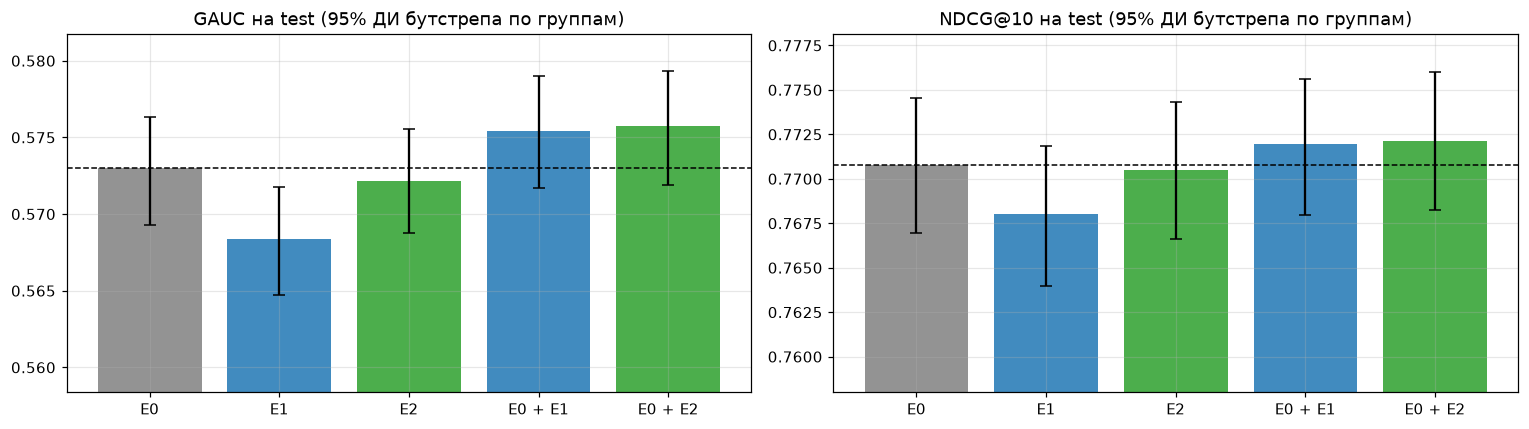

In [ ]:
lgb_names = [n for n, *_ in MODELS if "LightGBM" in n]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, (j, met) in zip(axes, enumerate(["GAUC", "NDCG@10"])):
    means = [PG[n][j].mean() for n in lgb_names]
    ci = []

    for n in lgb_names:
        bs = PG[n][j][idx].mean(1)
        #для yeer говорим, где начина.тся и заканчиваются усы
        ci.append((np.mean(PG[n][j]) - np.quantile(bs, 0.025), np.quantile(bs, 0.975) - np.mean(PG[n][j])))
    
    
    ax.bar(range(len(lgb_names)), means, yerr=np.array(ci).T, capsize=4,
           color=["gray", "C0", "C2", "C0", "C2"], alpha=0.85)
    ax.axhline(means[0], color="black", ls="--", lw=1)
    ax.set_xticks(range(len(lgb_names)), [n.replace(" LightGBM", "") for n in lgb_names])
    
    lo = min(means) - 0.01
    ax.set_ylim(lo, max(means) + 0.006)
    ax.set_title(f"{met} на test (95% ДИ бутстрепа по группам)")


plt.tight_layout()
plt.show()

## 3. Устойчивость: val_a → val_b → test

Модели и признаки выбирались по val_a. Если на val_b и test картина та же, выводы не являются подгонкой под одну неделю. Абсолютный уровень GAUC от недели к неделе может немного меняться (дрейф: доля label растёт от 0.689 на val_a до 0.714 на test), поэтому смотрим прежде всего на **разницы** с E0.

модель,val_a,val_b,test
str,f64,f64,f64
"""E2 LightGBM""",0.5759,0.5726,0.5722
"""E1 LightGBM""",0.5725,0.5692,0.5684
"""E0 + E2 LightGBM""",0.5769,0.5762,0.5757
"""E0 LightGBM""",0.574,0.569,0.573
"""E0 + E1 LightGBM""",0.5765,0.5733,0.5754


модель,val_a,val_b,test
str,f64,f64,f64
"""E2 LightGBM""",0.0019,0.0036,-0.0008
"""E1 LightGBM""",-0.0015,0.0002,-0.0046
"""E0 + E2 LightGBM""",0.0028,0.0072,0.0027
"""E0 LightGBM""",0.0,0.0,0.0
"""E0 + E1 LightGBM""",0.0025,0.0043,0.0024


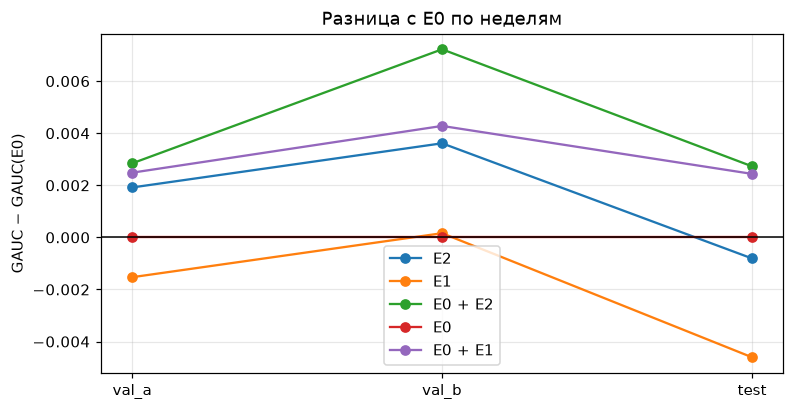

In [ ]:
#vertical relaxexd - мноугт чутка различаться типы, но склейка будет
val = pl.concat([R[e]["metrics"] for e in R], how="vertical_relaxed")
#имена в E0 различаеются, пожтому проверка
val = val.with_columns(pl.when(pl.col("модель").is_in(["LightGBM", "логрегрессия"]))
                       .then("E0 " + pl.col("модель")).otherwise(pl.col("модель")).alias("модель")).unique(["модель", "часть"])


#добавляем test и оставляем бустинг
allp = pl.concat([val.select("модель", "часть", "gauc", "ndcg@10", "logloss"),
                  test_m.select("модель", pl.lit("test").alias("часть"), "gauc", "ndcg@10", "logloss")])
allp = allp.filter(pl.col("модель").str.contains("LightGBM"))


#разница с E0 на каждой неделе
e0 = allp.filter(pl.col("модель") == "E0 LightGBM").select("часть", pl.col("gauc").alias("g0"))
gap = (allp.join(e0, on="часть").with_columns((pl.col("gauc") - pl.col("g0")).alias("Δ GAUC к E0"))
       .pivot(on="часть", index="модель", values="Δ GAUC к E0").select("модель", "val_a", "val_b", "test"))


display(allp.pivot(on="часть", index="модель", values="gauc").select("модель", "val_a", "val_b", "test").with_columns(pl.col(pl.Float64).round(4)))
display(gap.with_columns(pl.col(pl.Float64).round(4)))

fig, ax = plt.subplots(figsize=(8, 4))
for n in gap["модель"]:
    r = gap.filter(pl.col("модель") == n)
    ax.plot(["val_a", "val_b", "test"], [r["val_a"][0], r["val_b"][0], r["test"][0]], "o-", label=n.replace(" LightGBM", ""))
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("GAUC − GAUC(E0)")
ax.legend()
ax.set_title("Разница с E0 по неделям")
plt.show()

- E0 + E1 и E0 + E2 лучше E0 на всех трёх неделях. Это самый надёжный вывод работы.
- E2 один на валидации выглядел лучше E0 (на val_b даже значимо), а на test разница исчезла
- E1 один близок к E0 или немного хуже. На test отставание значимое

## 4. Сегменты на test: длина истории пользователя

In [ ]:
def bucket(col, edges, labels):
    e = pl.lit(labels[-1])
    for edge, lab in reversed(list(zip(edges, labels[:-1]))):
        e = pl.when(pl.col(col) <= edge).then(pl.lit(lab)).otherwise(e)
    return e


seg = pred.join(X.select("row_id", "u_listen_all"), on="row_id", how="left", maintain_order="left").with_columns(
    seg=bucket("u_listen_all", [500, 2000, 8000], ["a) < 500", "b) 500–2k", "c) 2k–8k", "d) > 8k"]))

rows = []
for s in seg["seg"].unique().sort().to_list():
    x = seg.filter(pl.col("seg") == s)
    rows.append({"история пользователя": s, "доля строк": round(x.height / seg.height, 3),
                 **{n.replace(" LightGBM", ""): round(evaluate(x, n)["gauc"], 4) for n in lgb_names}})
pl.DataFrame(rows)

история пользователя,доля строк,E0,E1,E2,E0 + E1,E0 + E2
str,f64,f64,f64,f64,f64,f64
"""a) < 500""",0.032,0.5304,0.5348,0.5404,0.5376,0.5309
"""b) 500–2k""",0.113,0.5601,0.5503,0.553,0.5586,0.5561
"""c) 2k–8k""",0.384,0.5731,0.5681,0.5713,0.5748,0.5757
"""d) > 8k""",0.471,0.5827,0.5794,0.584,0.5868,0.5883


Значимость разниц внутри сегментов: тот же парный бутстреп по группам «пользователь × день», что в разделе 2, но отдельно в каждом сегменте. Сегмент задан на начало дня, поэтому группа целиком попадает в один сегмент. В ячейке: разница GAUC с E0 и 95% ДИ; ✱ — интервал не содержит 0.

In [ ]:
srows = []

for s in seg["seg"].unique().sort().to_list():
    x = seg.filter(pl.col("seg") == s)
    pg = {n: per_group(x, n)[0] for n in lgb_names}
    g = len(pg["E0 LightGBM"])
    sidx = np.random.default_rng(1).integers(0, g, (1000, g))

    for n in lgb_names[1:]:
        diff = pg[n] - pg["E0 LightGBM"]
        lo, hi = np.quantile(diff[sidx].mean(1), [0.025, 0.975])
        srows.append({"история пользователя": s, "групп": g, "модель": n.replace(" LightGBM", ""),
                      "Δ GAUC": float(diff.mean()), "lo": float(lo), "hi": float(hi), "значимо": bool(lo > 0 or hi < 0)})


seg_boot = pl.DataFrame(srows)
(seg_boot.with_columns(cell=pl.format("{} [{}; {}]{}", pl.col("Δ GAUC").round(4), pl.col("lo").round(4), pl.col("hi").round(4),
                                      pl.when(pl.col("значимо")).then(pl.lit(" ✱")).otherwise(pl.lit(""))))
 .pivot(on="модель", index=["история пользователя", "групп"], values="cell"))

история пользователя,групп,E1,E2,E0 + E1,E0 + E2
str,i64,str,str,str,str
"""a) < 500""",702,"""0.0044 [-0.0093; 0.0176]""","""0.01 [-0.004; 0.0259]""","""0.0071 [-0.0042; 0.0181]""","""0.0005 [-0.0127; 0.0133]"""
"""b) 500–2k""",2219,"""-0.0098 [-0.0177; -0.0019] ✱""","""-0.0071 [-0.0159; 0.0008]""","""-0.0015 [-0.0089; 0.0051]""","""-0.004 [-0.0116; 0.0034]"""
"""c) 2k–8k""",6448,"""-0.005 [-0.0091; -0.0007] ✱""","""-0.0017 [-0.0061; 0.0026]""","""0.0017 [-0.0014; 0.005]""","""0.0027 [-0.0009; 0.0068]"""
"""d) > 8k""",5977,"""-0.0033 [-0.0068; 0.0001]""","""0.0013 [-0.0022; 0.0045]""","""0.0041 [0.0014; 0.007] ✱""","""0.0056 [0.0024; 0.0086] ✱"""


- Выигрыш E0 + авто значим только у пользователей с длинной историей
- «На средних историях ручные признаки лучше» подтвердилось только для E1. Он значимо хуже E0 в сегментах 500–2k и 2k–8k
- Сегмент < 500 — шум, как и ожидалось. Интервалы там шириной ±0.013, ни одно отличие не значимо

## 5. Итоговая таблица: качество и стоимость

Время на этом ноутбуке (CPU, 10 потоков, ~7.6 ГБ RAM). «Поиск» — разовая цена автоматизации (отбор признаков в E1, подбор h в E2); у E0 её место занимает ручная работа, которую в секундах не измерить.

In [8]:
c0, c1, c2 = R["E0"]["cost"], R["E1"]["cost"], R["E2"]["cost"]
tm = {r["модель"]: r for r in test_m.iter_rows(named=True)}
summary = pl.DataFrame([
    {"эксперимент": "E0 ручные", "признаков": len(E0_FEATURES), "генерация, с": c0["feature_time_s"], "поиск, с": 0.0,
     "обучение LGB, с": c0["lgb_train_s"], **{k: tm["E0 LightGBM"][k] for k in ["logloss", "roc_auc", "gauc", "ndcg@10"]}},
    {"эксперимент": "E1 грамматика + отбор", "признаков": c1["n_features"], "генерация, с": c1["generation_s"],
     "поиск, с": c1["filter_s"] + c1["rank_s"] + c1["greedy_s"], "обучение LGB, с": c1["lgb_E1_s"],
     **{k: tm["E1 LightGBM"][k] for k in ["logloss", "roc_auc", "gauc", "ndcg@10"]}},
    {"эксперимент": "E2 затухающие счётчики", "признаков": c2["n_features"], "генерация, с": c2["generation_s"],
     "поиск, с": c2["tuning_s"], "обучение LGB, с": c2["lgb_E2_s"],
     **{k: tm["E2 LightGBM"][k] for k in ["logloss", "roc_auc", "gauc", "ndcg@10"]}},
    {"эксперимент": "E0 + E2", "признаков": len(E0_FEATURES) + c2["n_features"], "генерация, с": c0["feature_time_s"] + c2["generation_s"] / 8,
     "поиск, с": c2["tuning_s"], "обучение LGB, с": c2["lgb_E0 + E2_s"],
     **{k: tm["E0 + E2 LightGBM"][k] for k in ["logloss", "roc_auc", "gauc", "ndcg@10"]}},
]).with_columns(pl.col("генерация, с", "поиск, с", "обучение LGB, с").round(0), pl.col("logloss", "roc_auc", "gauc", "ndcg@10").round(4))
summary

эксперимент,признаков,"генерация, с","поиск, с","обучение LGB, с",logloss,roc_auc,gauc,ndcg@10
str,i64,f64,f64,f64,f64,f64,f64,f64
"""E0 ручные""",36,39.0,0.0,51.0,0.4553,0.8228,0.573,0.7708
"""E1 грамматика + отбор""",10,111.0,2525.0,21.0,0.4563,0.8188,0.5684,0.768
"""E2 затухающие счётчики""",48,287.0,552.0,65.0,0.4522,0.822,0.5722,0.7705
"""E0 + E2""",84,75.0,552.0,98.0,0.4465,0.8275,0.5757,0.7721


Генерация E2 в строке «E0 + E2» — одно h (без перебора сетки), так как для применения нужна только выбранная конфигурация; генерация E1 и E2 в своих строках — вся сетка, по которой шёл поиск.

In [9]:
with open(A / "final_test.pkl", "wb") as f:
    pickle.dump({"test_metrics": test_m, "bootstrap": boot, "gap": gap, "summary": summary, "segments": seg_boot, "predictions": pred}, f)
print("Сохранено:", (A / "final_test.pkl").relative_to(ROOT))

Сохранено: artifacts/final_test.pkl


## 6. Выводы

**Test (LightGBM, разница GAUC с E0, 95% ДИ бутстрепа по группам):**

| эксперимент | признаков | GAUC | Δ к E0 | значимо | NDCG@10 | LogLoss |
|---|---|---|---|---|---|---|
| E0 ручные | 36 | 0.5730 | — | — | 0.771 | 0.455 |
| E1 грамматика + отбор | 10 | 0.5684 | −0.0046 [−0.0071; −0.0022] | да, хуже | 0.768 | 0.456 |
| E2 затухающие счётчики | 48 | 0.5722 | −0.0008 [−0.0031; +0.0019] | нет | 0.771 | **0.452** |
| E0 + E1 | 46 | 0.5754 | +0.0024 [+0.0005; +0.0045] | да, лучше | 0.772 | 0.450 |
| **E0 + E2** | 84 | **0.5757** | **+0.0027** [+0.0005; +0.0048] | да, лучше | **0.772** | **0.447** |

**1. Ответ на вопрос задания.** Ручные признаки **можно автоматизировать без потери качества**: затухающие счётчики (E2) — без ручного выбора окон, с одним подобранным числом h — дают то же качество ранжирования, что и ручной набор (разница −0.0008, незначима), и лучший LogLoss среди одиночных наборов. Автоматический отбор из грамматики (E1) даёт в 3.6 раза более компактную модель, но на test немного уступает (−0.0046 GAUC, значимо). E2 значимо лучше E1 (+0.0038 [+0.0016; +0.0059]).

**2. Самый устойчивый результат — автоматика вместе с ручными признаками.** E0 + E2 и E0 + E1 лучше E0 на **всех трёх** неделях (val_a, val_b, test): +0.002…+0.007 GAUC. Автоматический поиск находит то, чего нет в ручном наборе: длинную память (90 дней, вся история, затухание с h = 120), срезы только по рекомендациям, пару «пользователь × длина трека».

**3. Одной недели валидации мало.** На val_b E2 выглядел значимо лучше E0 (+0.0036), на test разницы нет. Разница E2 − E0 по неделям: +0.0019 → +0.0036 → −0.0008; у E0 на val_b был «провал» (0.569 против 0.574 и 0.573 на соседних неделях). Поэтому в отчёте сильными считаем только выводы, которые держатся на всех трёх неделях, — это пункт 2 и «E2 не хуже E0», «E2 лучше E1».

**4. Стоимость.** Автоматизация переносит работу с человека на машину: поиск — 42 мин у E1 (жадный отбор, ~800 обучений лёгкой модели) и 9 мин у E2 (подбор h, 65 обучений). E2 дешевле в поиске и проще (одна «ручка» h вместо выбора окон), E1 — компактнее в применении (10 признаков, обучение 21 с).

**5. Логрегрессия** на всех наборах отстаёт от LightGBM на ~0.007–0.009 GAUC; разрыв почти не зависит от набора признаков (H8 не подтвердилась: автоматические признаки не «спрямляют» задачу для линейной модели).


**6. Сегменты по длине истории.** GAUC растёт с длиной истории у всех моделей (0.53 у < 500 прослушиваний → 0.58–0.59 у > 8 тыс.): у «почти холодных» пользователей подход «признаки из истории» работает чуть лучше случайного — общее ограничение, а не свойство одного эксперимента. Значимый выигрыш E0 + E1 и E0 + E2 даёт сегмент > 8 тыс. (+0.004 и +0.006, 47% строк); в 2k–8k знак тот же, но интервал задевает 0. E1 значимо хуже E0 на средних историях (500–2k: −0.010; 2k–8k: −0.005). Сегмент < 500 (702 группы) слишком мал: интервалы ±0.013, порядок моделей в нём не интерпретируем.